# Weight decoders are linear maps over GF(2)

A 4-bit weight format like NVFP4 packs eight E2M1 codes into each 32-bit word. Before the math, a kernel turns those
codes into 16-bit values with a handful of bit operations: masks, shifts, rotates. Every recipe that only *moves and
selects* bits is a **linear map over GF(2)**, the field of single bits where addition is XOR:

$$
D : \mathbb{F}_2^{32} \to \mathbb{F}_2^{32}, \qquad y = D\,w \pmod 2, \qquad y_i = \bigoplus_{j} D_{ij}\, w_j .
$$

That turns a messy design space into linear algebra:

* **equality** of two decoders is equality of matrices, a check over the 32 basis words that covers all $2^{32}$ inputs;
* **composition** is matrix product, so a decoder after a repacking is $D \circ T$;
* **a new decoder comes with its packing.** If $P$ is the reference decode and $D$ is invertible, the repacking that makes
  $D$ produce exactly the same values is

$$
D\,T = P \quad\Longrightarrow\quad T = D^{-1} P .
$$

In CuTe terms the map is `Layout((2,)*32, F2-strides)`: the stride of input bit $j$ is the image of the basis vector
$e_j$, the $j$-th column of $D$.

In [1]:
import sys; sys.path[:0] = ['..', '.']
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note

MASK, FIELDS = 0x81C081C0, (6, 7, 8, 15, 22, 23, 24, 31)   # bit positions the decode writes in each output word
rotl = lambda q, k: ((q << (k % 32)) | (q >> ((32 - k % 32) % 32))) & 0xFFFFFFFF

def nvfp4_decode(q):
    # One packed word of eight 4-bit codes -> four output words, each holding two codes' sign/exponent/mantissa bits
    return (q & MASK, (q << 4) & MASK, rotl(q, 10) & MASK, ((q << 6) & 0x80C080C0) | (rotl(q, 14) & 0x01000100))

def as_matrix(fn):
    images = [fn(1 << j) for j in range(32)]
    return tuple(sum(((images[j][r] >> b) & 1) << j for j in range(32)) for r in range(4) for b in FIELDS)

P = as_matrix(nvfp4_decode)
bits = lambda rows: np.array([[(r >> j) & 1 for j in range(32)] for r in rows])
print("rank of the reference decode:", xc.rank(P), "of 32")

rank of the reference decode: 32 of 32


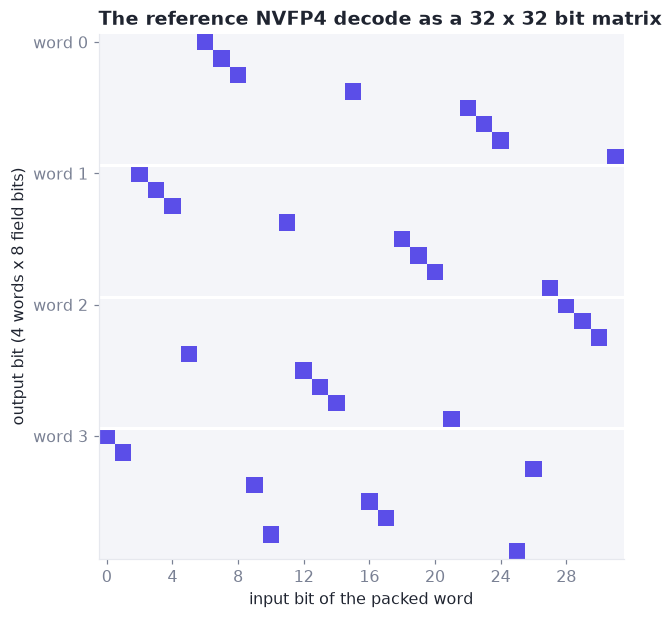

In [2]:
fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.imshow(bits(P), cmap=plt.matplotlib.colors.ListedColormap(["#f4f5f9", C["ours"]]))
ax.set_title("The reference NVFP4 decode as a 32 x 32 bit matrix")
ax.set_xlabel("input bit of the packed word"); ax.set_ylabel("output bit (4 words x 8 field bits)")
ax.set_xticks(range(0, 32, 4)); ax.set_yticks(range(0, 32, 8), ["word 0", "word 1", "word 2", "word 3"])
ax.grid(False)
for y in (7.5, 15.5, 23.5): ax.axhline(y, color="white", lw=2)
save(fig, "gf2_reference_decode"); plt.show()

## A new decoder and its proven packing

Take a decoder that reads the packed word rotated by 8 bits first: $D = P \circ R_8$. It produces different values from
the same bits, but $T = D^{-1}P$ repacks the weights in `prepare()` so that $D(T(w)) = P(w)$ for **every** word.
Here $T$ turns out to be a permutation: a pure bit shuffle, exactly the kind of lossless repacking the rules allow.

D(T(w)) == P(w) on 2,000 random words: True
T is a permutation: True


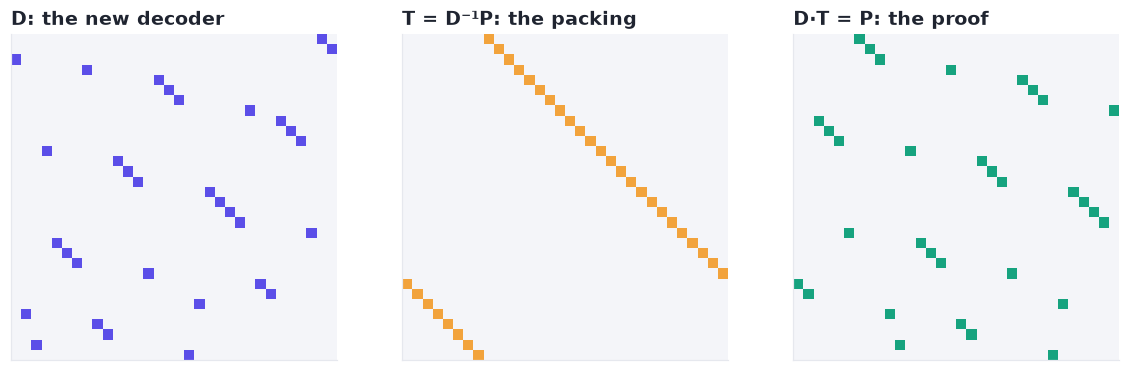

In [3]:
D = xc.compose(P, xc.rotation(8))
T = xc.packing_transform(D, P)
rng = np.random.default_rng(0)
words = [int(w) for w in rng.integers(0, 2**32, 2000)]
print("D(T(w)) == P(w) on 2,000 random words:", all(xc.apply(D, xc.apply(T, w)) == xc.apply(P, w) for w in words))
print("T is a permutation:", all(bin(r).count("1") == 1 for r in T))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
cmap = plt.matplotlib.colors.ListedColormap(["#f4f5f9", C["ours"]])
for ax, (name, M, col) in zip(axes, [("D: the new decoder", D, C["ours"]), ("T = D⁻¹P: the packing", T, C["accent"]),
                                        ("D·T = P: the proof", xc.compose(D, T), C["good"])]):
    ax.imshow(bits(M), cmap=plt.matplotlib.colors.ListedColormap(["#f4f5f9", col])); ax.set_title(name); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
save(fig, "gf2_packing_proof"); plt.show()

## Searching the space exactly

The production grammar builds decoders from **atoms**: partial recipes that each produce some output fields. Two
atoms can be joined only if their rows stay linearly independent, so a pairwise-compatibility bitset prunes the
product before any combination is built:

$$
\text{legal} = \{\, a_1 \cup \dots \cup a_k \;:\; \operatorname{rank}\big(\textstyle\bigcup_i a_i\big) = 32,\ \text{pairwise compatible} \,\}.
$$

On an H200 this exhausted **5,989,005** raw combinations to **1,816** legal decoder graphs in about **1.3 ms** [M].
Each one is a candidate kernel with a proven packing, and the measured search later found one that, combined with a
different dequant arithmetic, gave **+3.3%** on the one-token load (each piece alone: +0.4% and +0.9%).

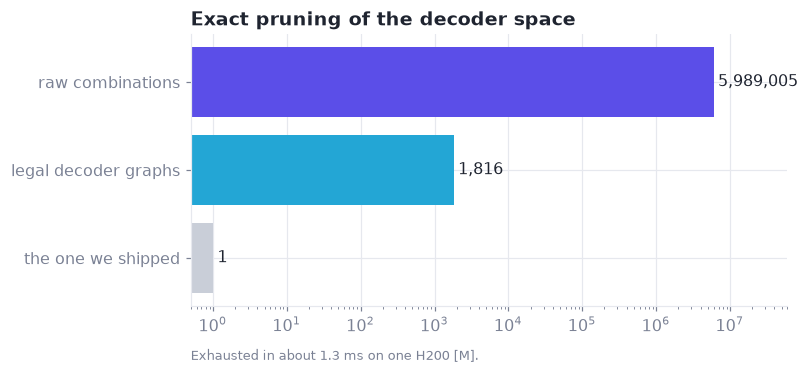

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
vals, labels = [5_989_005, 1_816, 1], ["raw combinations", "legal decoder graphs", "the one we shipped"]
ax.barh(labels[::-1], vals[::-1], color=[C["ours"], C["cyan"], C["sglang"]][::-1])
ax.set_xscale("log"); ax.set_title("Exact pruning of the decoder space")
for i, v in enumerate(vals[::-1]): ax.text(v * 1.15, i, f"{v:,}", va="center", color=INK)
ax.set_xlim(0.5, 6e7); note(ax, "Exhausted in about 1.3 ms on one H200 [M].")
save(fig, "gf2_search_space"); plt.show()

## The CuTe view

The same map as a CuTe layout: shape $(2,)^{32}$, strides in $\mathbb{F}_2^{32}$. The stride of input bit $j$ is the
column $D e_j$. Evaluating the layout at a coordinate (the bits of $w$) XORs the strides of the set bits, which is
$D w$.

In [5]:
strides = xc.columns(P)
print("first eight F2 strides (hex):", [hex(s) for s in strides[:8]])
w = 0x12345678
acc = 0
for j in range(32):
    if (w >> j) & 1: acc ^= strides[j]
print("layout evaluation == matrix application:", acc == xc.apply(P, w))
try:
    print(xc.as_cute_layout(P))
except ImportError:
    print("(install NVIDIA's pycute to print the same object as a CuTe Layout)")

first eight F2 strides (hex): ['0x1000000', '0x2000000', '0x100', '0x200', '0x400', '0x80000', '0x1', '0x2']
layout evaluation == matrix application: True
(install NVIDIA's pycute to print the same object as a CuTe Layout)
